# 01 - Data Exploration: Telco Customer Churn
**Goal:** understand the data, check quality, spot leakage, and see where churn concentrates *before* modelling (see `02_churn_modeling.ipynb`).

## 1. Load data

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_excel("../data/Telco_customer_churn.xlsx")
df.columns = df.columns.str.strip().str.replace(" ", "_")
print("Shape:", df.shape)
df.head()

OUT_DIR = Path("../outputs")
OUT_DIR.mkdir(exist_ok=True)

Shape: (7043, 33)


## 2. Data types and quality checks

In [2]:
print(df.dtypes.to_string())
print("\nMissing values per column:")
missing = df.isna().sum()
print(missing[missing > 0].to_string())
print("\nDuplicate customer IDs:", df["CustomerID"].duplicated().sum())

# Total_Charges is stored as text because of blank strings
tc = pd.to_numeric(df["Total_Charges"], errors="coerce")
print("\nBlank/non-numeric Total_Charges:", tc.isna().sum())
print("Their tenure (months):", df.loc[tc.isna(), "Tenure_Months"].unique())

# Columns with a single value carry no information
const = [c for c in df.columns if df[c].nunique() == 1]
print("\nConstant columns:", const)

CustomerID               str
Count                  int64
Country                  str
State                    str
City                     str
Zip_Code               int64
Lat_Long                 str
Latitude             float64
Longitude            float64
Gender                   str
Senior_Citizen           str
Partner                  str
Dependents               str
Tenure_Months          int64
Phone_Service            str
Multiple_Lines           str
Internet_Service         str
Online_Security          str
Online_Backup            str
Device_Protection        str
Tech_Support             str
Streaming_TV             str
Streaming_Movies         str
Contract                 str
Paperless_Billing        str
Payment_Method           str
Monthly_Charges      float64
Total_Charges         object
Churn_Label              str
Churn_Value            int64
Churn_Score            int64
CLTV                   int64
Churn_Reason             str

Missing values per column:
Churn_Reason   

**Findings**
- No duplicate customers.
- `Total_Charges` has 11 blank values, all for customers with tenure 0 (brand-new), so they are set to 0.
- `Churn_Reason` is missing for every customer who did **not** churn (5,174 rows). This is a leakage warning, see section 3.
- `Count`, `Country` and `State` are constant, so they are useless as features.

## 3. Leakage check

In [3]:
df["Churn_Value"] = df["Churn_Value"].astype(int)

print("Mean of IBM-supplied columns by churn outcome:")
print(df.groupby("Churn_Value")[["Churn_Score", "CLTV"]].mean().round(1))
print("\nShare of customers with a Churn_Reason, by outcome:")
print(df["Churn_Reason"].notna().groupby(df["Churn_Value"]).mean())

Mean of IBM-supplied columns by churn outcome:
             Churn_Score    CLTV
Churn_Value                     
0                   50.1  4490.9
1                   82.5  4149.4

Share of customers with a Churn_Reason, by outcome:
Churn_Value
0    0.0
1    1.0
Name: Churn_Reason, dtype: float64


**Findings: these columns must NOT be used as model features**
- `Churn_Reason` exists only for customers who already churned, so it reveals the answer.
- `Churn_Score` is the output of another churn model (much higher for churners), and `CLTV` is derived by IBM alongside it.
- `Churn_Label` and `Churn_Value` are the target itself.

They are used here only for description, never for prediction.

## 4. Target distribution

Churn_Value
0    5174
1    1869

Churn rate: 26.5%


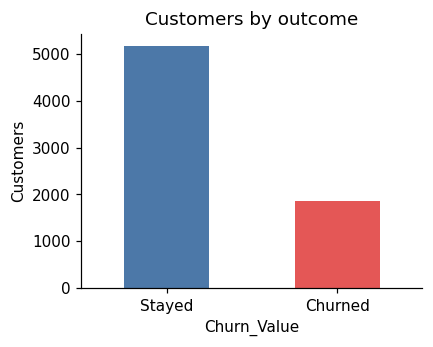

In [4]:
counts = df["Churn_Value"].value_counts().sort_index()
print(counts.to_string())
print(f"\nChurn rate: {df['Churn_Value'].mean():.1%}")
ax = counts.rename({0: "Stayed", 1: "Churned"}).plot.bar(rot=0, figsize=(4, 3), color=["#4c78a8", "#e45756"])
ax.set_title("Customers by outcome")
ax.set_ylabel("Customers")
plt.show()

The classes are imbalanced (about 26.5% churn). Accuracy alone would be misleading, so the model is judged on ROC-AUC and PR-AUC, and the contact threshold is chosen by business value.

## 5. Churn rate by categorical features

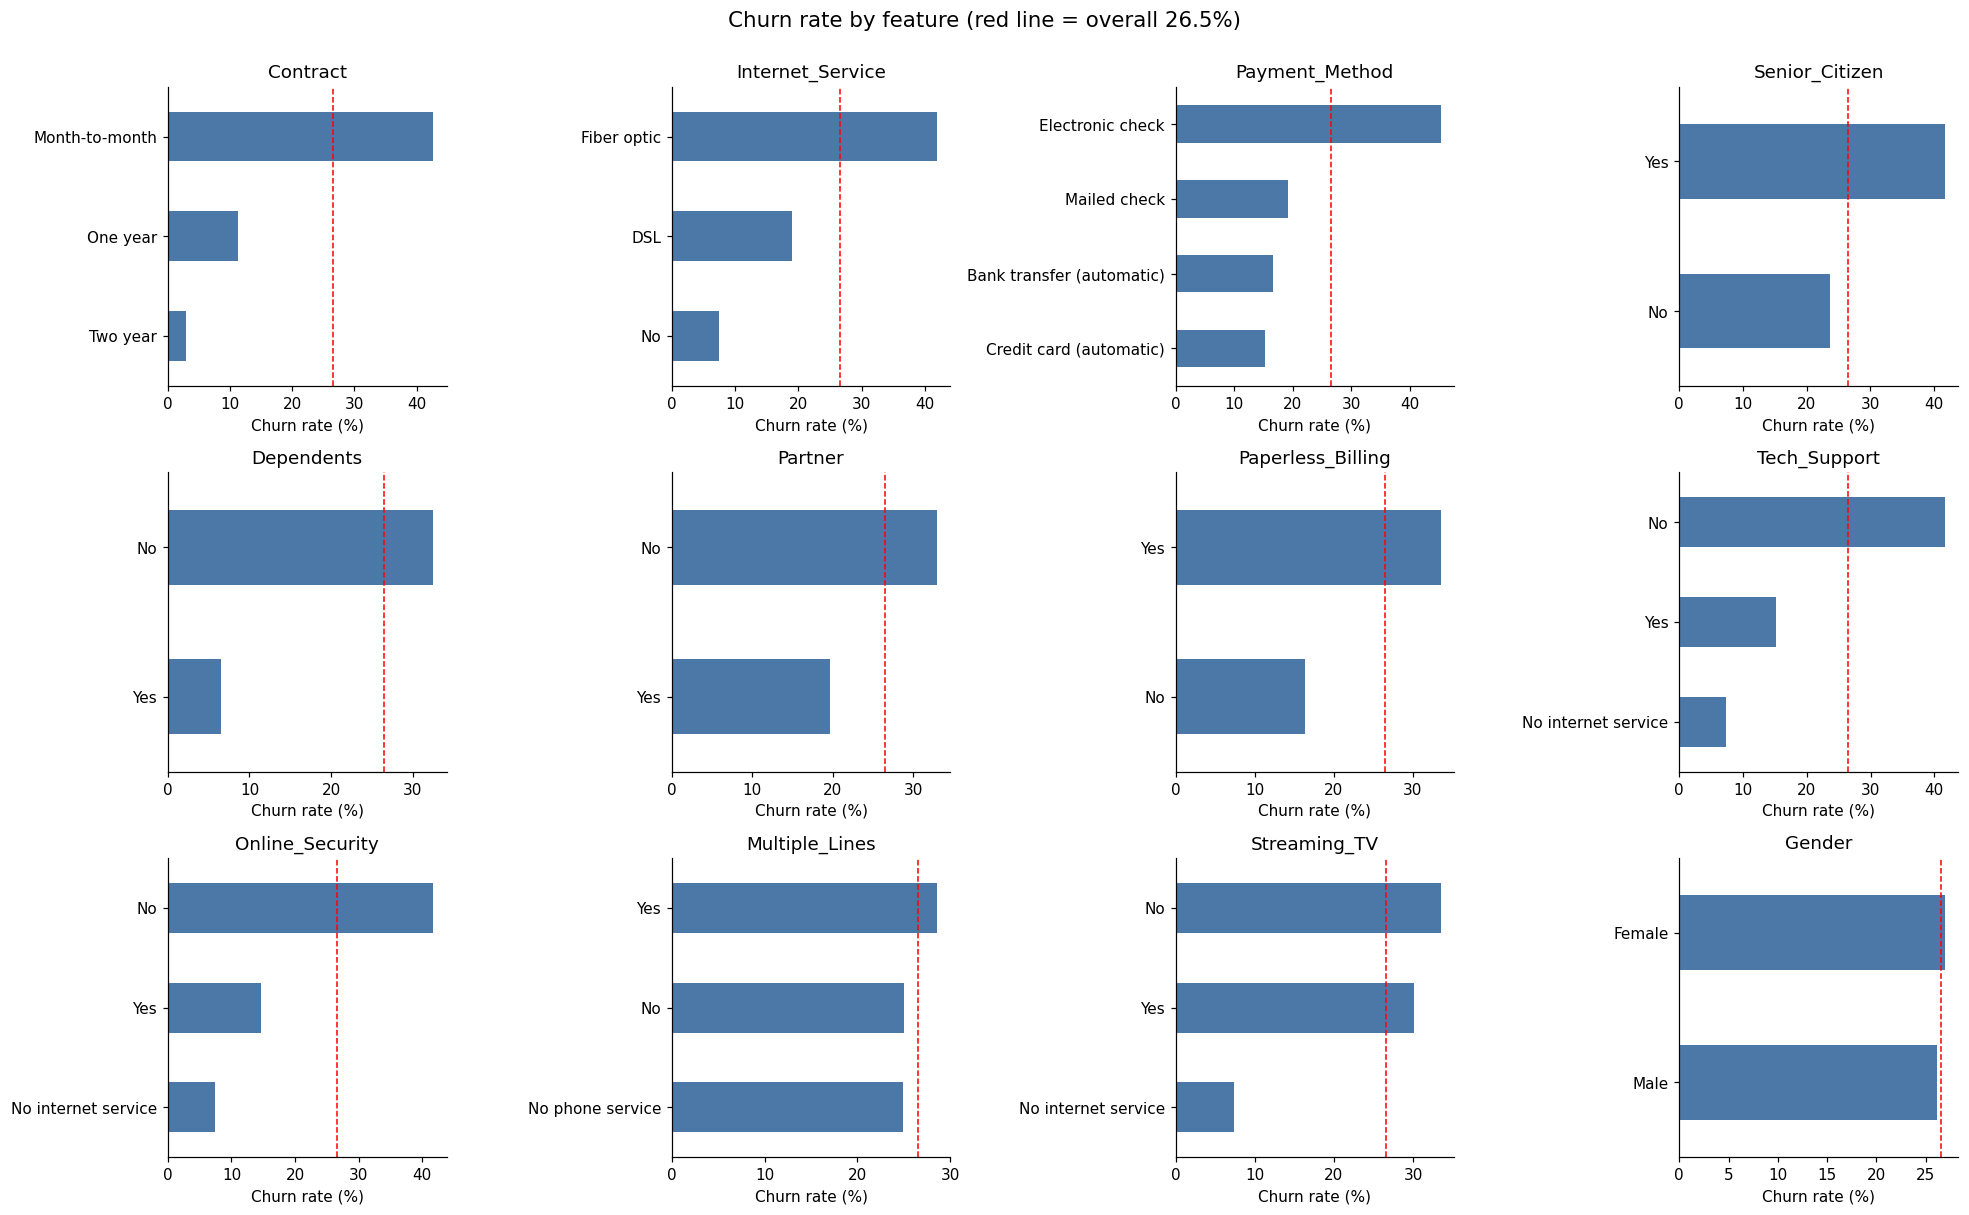

In [5]:
cat_cols = ["Contract", "Internet_Service", "Payment_Method", "Senior_Citizen",
            "Dependents", "Partner", "Paperless_Billing", "Tech_Support",
            "Online_Security", "Multiple_Lines", "Streaming_TV", "Gender"]
overall = df["Churn_Value"].mean() * 100

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, col in zip(axes.ravel(), cat_cols):
    rates = df.groupby(col)["Churn_Value"].mean().mul(100).sort_values()
    rates.plot.barh(ax=ax, color="#4c78a8")
    ax.axvline(overall, color="red", ls="--", lw=1)
    ax.set_title(col)
    ax.set_xlabel("Churn rate (%)")
    ax.set_ylabel("")
fig.suptitle(f"Churn rate by feature (red line = overall {overall:.1f}%)", y=1.0, fontsize=14)
plt.tight_layout()
plt.savefig(OUT_DIR / "eda_churn_by_feature.png", dpi=150, bbox_inches="tight")
plt.show()

**Findings**
- **Contract:** month-to-month 42.7%, one-year 11.3%, two-year 2.8%. The strongest single signal.
- **Internet service:** fibre optic 41.9%, DSL 19.0%, no internet 7.4%.
- **Payment method:** electronic check 45.3% vs 15-19% for the other three methods.
- **Senior citizens** churn at 41.7% vs 23.6%; customers **with dependents** churn at only 6.5% vs 32.6%.
- **Tech support:** 41.6% churn without it vs 15.2% with it. Paperless billing: 33.6% vs 16.3%.
- **Gender** shows essentially no difference, so it is excluded from the model.

## 6. Numeric features: tenure and charges

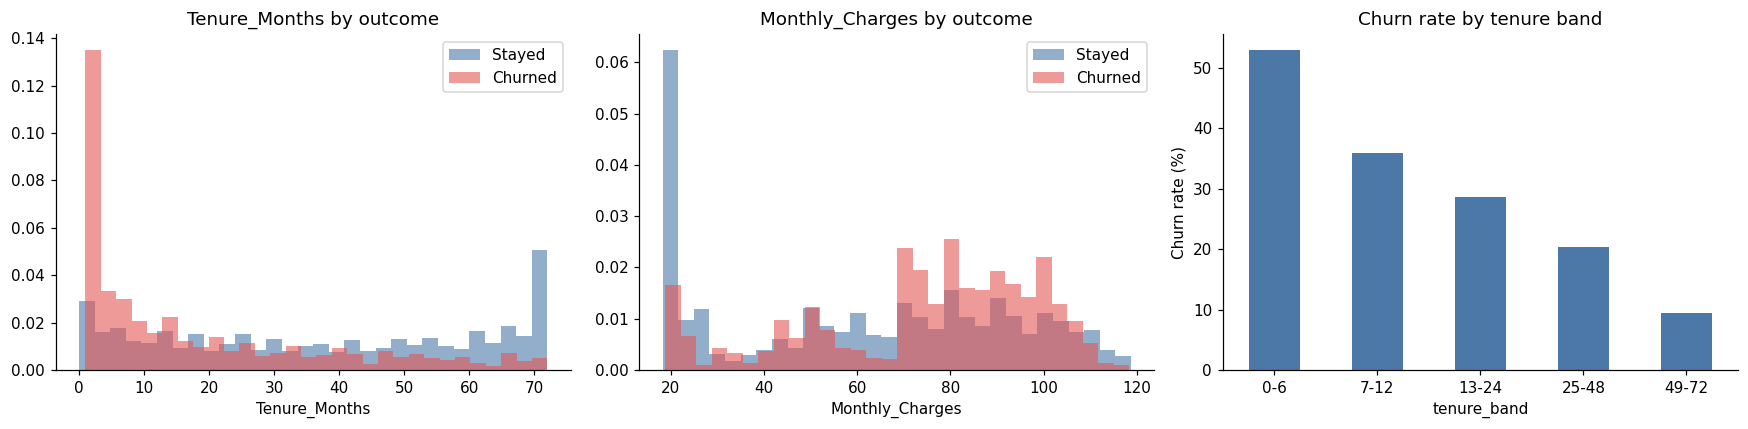

             Tenure_Months  Monthly_Charges
Churn_Value                                
0                     37.6             61.3
1                     18.0             74.4


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Tenure_Months", "Monthly_Charges"]):
    for val, label, colour in [(0, "Stayed", "#4c78a8"), (1, "Churned", "#e45756")]:
        ax.hist(df.loc[df["Churn_Value"] == val, col], bins=30, alpha=0.6,
                label=label, color=colour, density=True)
    ax.set_title(f"{col} by outcome")
    ax.set_xlabel(col)
    ax.legend()

df["tenure_band"] = pd.cut(df["Tenure_Months"], [-1, 6, 12, 24, 48, 72],
                           labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
(df.groupby("tenure_band", observed=True)["Churn_Value"].mean().mul(100)
   .plot.bar(ax=axes[2], rot=0, color="#4c78a8"))
axes[2].set_title("Churn rate by tenure band")
axes[2].set_ylabel("Churn rate (%)")
plt.tight_layout()
plt.show()

print(df.groupby("Churn_Value")[["Tenure_Months", "Monthly_Charges"]].mean().round(1))

**Findings**
- Churn falls steadily with tenure: 52.9% in the first 6 months, 35.9% for months 7-12, down to 9.5% beyond 4 years.
- Churners have much shorter tenure (average 18 vs 38 months) and pay more per month (about $74 vs $61).
- So the highest-risk profile is a **new customer on a pricey plan with no commitment**.

## 7. Combining the two biggest drivers: contract x internet service

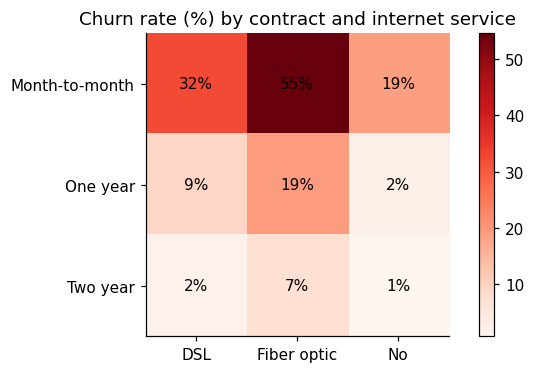

In [7]:
pivot = df.pivot_table(index="Contract", columns="Internet_Service",
                       values="Churn_Value", aggfunc="mean") * 100
fig, ax = plt.subplots(figsize=(6, 3.5))
im = ax.imshow(pivot.values, cmap="Reds")
ax.set_xticks(range(pivot.shape[1]), pivot.columns)
ax.set_yticks(range(pivot.shape[0]), pivot.index)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        ax.text(j, i, f"{pivot.values[i, j]:.0f}%", ha="center", va="center")
ax.set_title("Churn rate (%) by contract and internet service")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

Month-to-month **fibre optic** customers churn at 54.6%, compared with 0.8% for two-year customers without internet. Contract length matters in every internet segment, which is why it is the top driver in the model.

## 8. Revenue view

In [8]:
df["annual_revenue"] = df["Monthly_Charges"] * 12
rev = df.groupby("Churn_Value")["annual_revenue"].sum()
print(f"Annualised revenue of churned customers: ${rev[1]:,.0f} "
      f"({rev[1] / rev.sum():.1%} of ${rev.sum():,.0f})")

Annualised revenue of churned customers: $1,669,570 (30.5% of $5,473,399)


Churned customers represent roughly 30% of annualised monthly-charge revenue. This is a simple proxy (12 x monthly charges), not a financial forecast.

## 9. Why do customers say they left?

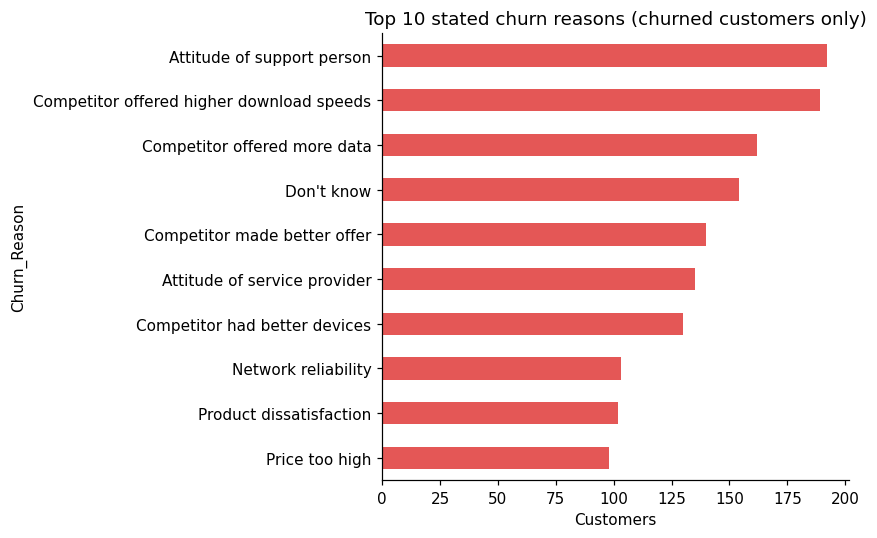

In [9]:
reasons = df["Churn_Reason"].value_counts().head(10).sort_values()
reasons.plot.barh(figsize=(8, 5), color="#e45756", title="Top 10 stated churn reasons (churned customers only)")
plt.xlabel("Customers")
plt.tight_layout()
plt.savefig(OUT_DIR / "churn_reasons.png", dpi=150)
plt.show()

The most common reasons point to **competitor offers** (download speed, data allowance, better deal) and **support-staff attitude**. These are actionable by marketing, pricing and customer service, which is not always true of demographic drivers.

## 10. Build the cleaned dataset for modelling
This applies the decisions from the findings above and saves `data/processed/telco_clean.csv`, which **notebook 02 loads directly**. Everything here is row-wise (no statistics learned from the data), so it is safe to do before the train/test split.

- **Dropped:** leakage columns (`Churn_Label`, `Churn_Score`, `CLTV`), constant/location columns, and `Gender`.
- **Kept for description only:** `Churn_Reason` (never used as a model feature) and `CustomerID` (identifier).
- **Fixed:** blank `Total_Charges` set to 0; "No internet/phone service" recoded to "No"; Yes/No columns turned into 1/0.
- **Engineered:** `n_protection_services`, `n_streaming_services`, `is_new_customer`.

In [10]:
raw = pd.read_excel("../data/Telco_customer_churn.xlsx")
raw.columns = raw.columns.str.strip().str.replace(" ", "_")

DROP = ["Churn_Label", "Churn_Score", "CLTV",                      # leakage / duplicate of target
        "Count", "Country", "State", "City", "Zip_Code",           # constant or high-cardinality
        "Lat_Long", "Latitude", "Longitude",
        "Gender"]                                                  # no business justification
clean = raw.drop(columns=DROP).copy()

clean["Total_Charges"] = pd.to_numeric(clean["Total_Charges"], errors="coerce").fillna(0)

yes_no = ["Senior_Citizen", "Partner", "Dependents", "Phone_Service", "Paperless_Billing", "Multiple_Lines"]
addons = ["Online_Security", "Online_Backup", "Device_Protection", "Tech_Support", "Streaming_TV", "Streaming_Movies"]
for c in yes_no + addons:
    clean[c] = (clean[c] == "Yes").astype(int)

clean["n_protection_services"] = clean[["Online_Security", "Online_Backup", "Device_Protection", "Tech_Support"]].sum(axis=1)
clean["n_streaming_services"] = clean[["Streaming_TV", "Streaming_Movies"]].sum(axis=1)
clean["is_new_customer"] = (clean["Tenure_Months"] <= 12).astype(int)

# Column order: id, features, target, descriptive-only reason
feature_cols = [c for c in clean.columns if c not in ["CustomerID", "Churn_Value", "Churn_Reason"]]
clean = clean[["CustomerID"] + feature_cols + ["Churn_Value", "Churn_Reason"]]

# Sanity checks
assert clean["CustomerID"].is_unique
assert clean[feature_cols].isna().sum().sum() == 0
assert not {"Churn_Score", "CLTV", "Churn_Label"} & set(clean.columns)
assert len(feature_cols) == 21

PROCESSED = Path("../data/processed")
PROCESSED.mkdir(parents=True, exist_ok=True)
clean.to_csv(PROCESSED / "telco_clean.csv", index=False)
print(f"Saved {clean.shape[0]:,} rows x {clean.shape[1]} columns to {PROCESSED / 'telco_clean.csv'}")
print("Features:", feature_cols)

Saved 7,043 rows x 24 columns to ../data/processed/telco_clean.csv
Features: ['Senior_Citizen', 'Partner', 'Dependents', 'Tenure_Months', 'Phone_Service', 'Multiple_Lines', 'Internet_Service', 'Online_Security', 'Online_Backup', 'Device_Protection', 'Tech_Support', 'Streaming_TV', 'Streaming_Movies', 'Contract', 'Paperless_Billing', 'Payment_Method', 'Monthly_Charges', 'Total_Charges', 'n_protection_services', 'n_streaming_services', 'is_new_customer']


## 11. Summary and next steps
**What the data says**
1. About 1 in 4 customers churn, and churn is concentrated in **month-to-month, fibre-optic, new, electronic-check** customers.
2. Long contracts, dependents, and add-ons like tech support are associated with retention.
3. Stated reasons highlight competitor pricing/speed and support quality.

**Decisions applied in section 10 and carried into notebook 02 via `data/processed/telco_clean.csv`**
- Drop leakage columns (`Churn_Score`, `Churn_Reason`, `CLTV`, label columns), constant/location columns and `Gender`.
- Convert `Total_Charges` to numeric (blank means 0), and recode "No internet/phone service" to "No" for add-ons.
- Handle the 26.5% class imbalance through ranking metrics (ROC-AUC, PR-AUC) and a business-driven threshold.

*These are associations in a single snapshot, not proof of cause.*